In [1]:
#Dla warstwy z rzekami policz ile jest obiektÄ‚Ĺ‚w ktÄ‚Ĺ‚rych MultiLineString zawiera dokÄąâ€šadnie miĂ„â„˘dzy 2 a 10 czĂ„â„˘Äąâ€şci skÄąâ€šadowych geometrii
import geopandas as gpd

path_to_files = "C:/Users/julia/Desktop/SDG/cwiczenia/dane/"

rivers = gpd.read_file(path_to_files+"hr1.geojson")
print(rivers.head())

rivers["liczba_linii"] = rivers.geometry.apply(lambda geom: len(geom.geoms))
print(rivers["liczba_linii"])

rivers_filtr = rivers[(rivers["liczba_linii"] >= 2) & (rivers["liczba_linii"] <= 10)]
print(len(rivers_filtr))



   gid       nazwa  typ   długość                                     opis  \
0    3  North Fork  NaN       NaN  Opis zostanie dodany w następnej wersji   
1  152       Indus  NaN  3 180 km  Opis zostanie dodany w następnej wersji   
2  239  Rio Grande  NaN  3 051 km  Opis zostanie dodany w następnej wersji   
3  357   Missisipi  NaN  3 766 km  Opis zostanie dodany w następnej wersji   
4  505       Niger  NaN  4 184 km  Opis zostanie dodany w następnej wersji   

  legenda                                             źródło  \
0   rzeka  Made with Natural Earth (www.naturalearthdata....   
1   rzeka  Made with Natural Earth (www.naturalearthdata....   
2   rzeka  Made with Natural Earth (www.naturalearthdata....   
3   rzeka  Made with Natural Earth (www.naturalearthdata....   
4   rzeka  Made with Natural Earth (www.naturalearthdata....   

                                            geometry  
0  MULTILINESTRING ((-151.67419 64.30139, -151.67...  
1  MULTILINESTRING ((67.66363 24.106

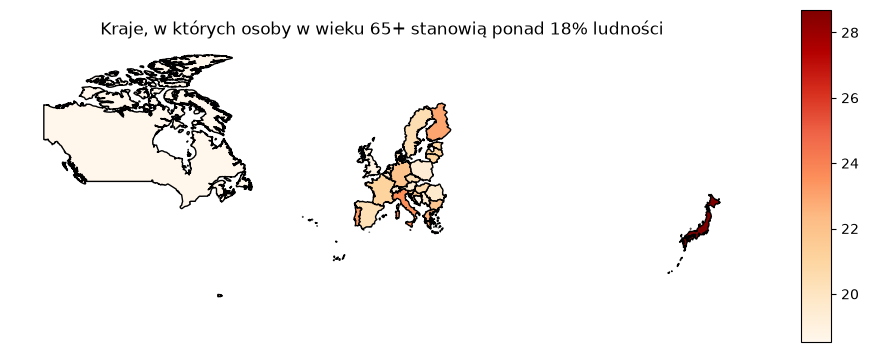

In [4]:
# Dla warstwy demograficznej wyświetl na mapie kraje, w których odsetek osób w wieku 65+ wynosi ponad 18%
import pandas as pd

demography = gpd.read_file(path_to_files + "lsp1.geojson")

column = "ludność_w_wieku_65_lat_i_więcej"
demography[column] = (
    demography[column]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
    .replace("brak danych", pd.NA)
)
demography[column] = pd.to_numeric(demography[column], errors="coerce")

demo_65 = demography[demography[column] > 18]

ax = demo_65.plot(column=column, legend=True, figsize=(12, 8), cmap="OrRd", edgecolor="black")
ax.set_title("Kraje, w których osoby w wieku 65+ stanowią ponad 18% ludności")
ax.set_axis_off()

In [13]:
# Dla warstwy z wulkanami stwórz podzbiór wulkanów znajdujących się w Stanach Zjednoczonych. 
# Następnie wypisz wszystkie typy wulkanów występujące w tym podzbiorze oraz oblicz, jaki procent wszystkich wulkanów w USA stanowi każdy z typów

volcanoes = gpd.read_file(path_to_files + "wulkany/" +"lw1.geojson")

volcanoes_usa = volcanoes[ volcanoes['kraj'] == 'Stany Zjednoczone']
v_type = list(volcanoes_usa['typ'].unique())
print(v_type)

procenty = volcanoes_usa['typ'].value_counts().to_dict()
procenty = {k:v / len(volcanoes_usa) * 100 for k,v in procenty.items()}
print(procenty, sep="\n")

['stratowulkan', 'stożkowy', 'podwodny', 'kopuła lawowa', 'maar', 'pole wulkaniczne', 'kaldera', 'mieszane, złożone', 'tarczowy']
{'stratowulkan': 51.19047619047619, 'tarczowy': 11.904761904761903, 'podwodny': 10.714285714285714, 'pole wulkaniczne': 8.928571428571429, 'stożkowy': 7.142857142857142, 'kopuła lawowa': 3.571428571428571, 'maar': 2.976190476190476, 'kaldera': 2.976190476190476, 'mieszane, złożone': 0.5952380952380952}
